# Compare Privacy vs Adaptive Federated Learning
combine the work from previous days and compare three models:
1. Standard FedAvg — normal federated learning.
2. Private FedAvg — federated learning with noise added to protect model updates.
3. Adaptive FedAvg — federated learning with different client weights.
The goal is to find out how privacy and adaptive weighting affect attack-detection performance.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch_geometric.nn import GCNConv
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

BASE = Path("D:/adaptive_federated_gnn")
OUT = BASE / "outputs/day20"
OUT.mkdir(parents=True, exist_ok=True)

graph = torch.load(
    BASE / "data/processed/edge_graph.pt",
    map_location="cpu",
    weights_only=False
)

edge_index = graph["edge_index"].long()
edge_features = graph["edge_attr"].float()
edge_labels = graph["edge_label"].long().view(-1)

num_nodes = int(edge_index.max().item()) + 1
num_edge_features = edge_features.shape[1]

day10_clients = torch.load(
    BASE / "outputs/day10/federated_clients.pt",
    map_location="cpu",
    weights_only=False
)

# Load the three previously saved models
model_paths = {
    "Standard FedAvg": BASE / "outputs/day19/standard_fedavg_model.pt",
    "Adaptive FedAvg": BASE / "outputs/day19/adaptive_fedavg_model.pt",
    "Private FedAvg": BASE / "outputs/day17/private_global_model.pt"
}

model_states = {}

for name, path in model_paths.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing model file: {path}")
    model_states[name] = torch.load(
        path, map_location="cpu", weights_only=False
    )

print("Graph loaded:", edge_index.shape[1], "edges")
print("Features per edge:", num_edge_features)
print("Models loaded:", list(model_states.keys()))
print("Output folder:", OUT)

c:\Users\daksh\anaconda3\envs\adaptive_gnn\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Graph loaded: 286095 edges
Features per edge: 67
Models loaded: ['Standard FedAvg', 'Adaptive FedAvg', 'Private FedAvg']
Output folder: D:\adaptive_federated_gnn\outputs\day20


In [2]:
class EdgeGCN(nn.Module):
    def __init__(
        self, num_nodes, edge_feature_size,
        embedding_size=16, hidden_size=32
    ):
        super().__init__()

        self.node_embeddings = nn.Embedding(num_nodes, embedding_size)
        self.conv1 = GCNConv(embedding_size, hidden_size)
        self.conv2 = GCNConv(hidden_size, hidden_size)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2 + edge_feature_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, edge_index, edge_features):
        node_ids = torch.arange(self.node_embeddings.num_embeddings)
        x = self.node_embeddings(node_ids)
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))

        source = x[edge_index[0]]
        destination = x[edge_index[1]]

        combined = torch.cat(
            [source, destination, edge_features], dim=1
        )
        return self.classifier(combined)

print("GNN architecture ready.")

GNN architecture ready.


In [3]:
train_indices = np.unique(np.concatenate([
    (
        data["local_edge_indices"].cpu().numpy()
        if torch.is_tensor(data["local_edge_indices"])
        else np.asarray(data["local_edge_indices"])
    )
    for data in day10_clients.values()
])).astype(np.int64)

train_indices = train_indices[
    (train_indices >= 0) & (train_indices < len(edge_labels))
]

train_mask = np.zeros(len(edge_labels), dtype=bool)
train_mask[train_indices] = True

test_indices = np.flatnonzero(~train_mask)
test_t = torch.tensor(test_indices, dtype=torch.long)
y_test = edge_labels[test_t].numpy()

if len(test_indices) == 0:
    raise ValueError("No test edges found.")

print("Training edges:", int(train_mask.sum()))
print("Test edges:", len(test_indices))
print("Benign test edges:", int((y_test == 0).sum()))
print("Attack test edges:", int((y_test == 1).sum()))

Training edges: 200266
Test edges: 85829
Benign test edges: 38188
Attack test edges: 47641


In [4]:
results = []
prediction_table = pd.DataFrame({
    "edge_index": test_indices,
    "actual_label": y_test
})

for name, state in model_states.items():
    model = EdgeGCN(num_nodes, num_edge_features)
    model.load_state_dict(state)
    model.eval()

    with torch.no_grad():
        logits = model(edge_index, edge_features)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        predictions = logits.argmax(dim=1)

    y_pred = predictions[test_t].numpy()
    y_prob = probabilities[test_t].numpy()

    row = {
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "roc_auc": (
            roc_auc_score(y_test, y_prob)
            if len(np.unique(y_test)) == 2 else np.nan
        ),
        "pr_auc": (
            average_precision_score(y_test, y_prob)
            if len(np.unique(y_test)) == 2 else np.nan
        )
    }
    results.append(row)

    safe_name = name.lower().replace(" ", "_")
    prediction_table[f"{safe_name}_prediction"] = y_pred
    prediction_table[f"{safe_name}_attack_probability"] = y_prob

comparison = pd.DataFrame(results)
comparison.to_csv(OUT / "three_model_metrics.csv", index=False)
prediction_table.to_csv(OUT / "three_model_predictions.csv", index=False)

display(comparison)
print("Metrics and predictions saved.")

,model,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,Standard FedAvg,0.413275,0.007968,0.000462,0.000873,0.876633,0.789229
1,Adaptive FedAvg,0.412786,0.007849,0.000462,0.000872,0.876200,0.788830
2,Private FedAvg,0.572790,0.565121,0.999475,0.722007,0.423266,0.469131


Metrics and predictions saved.


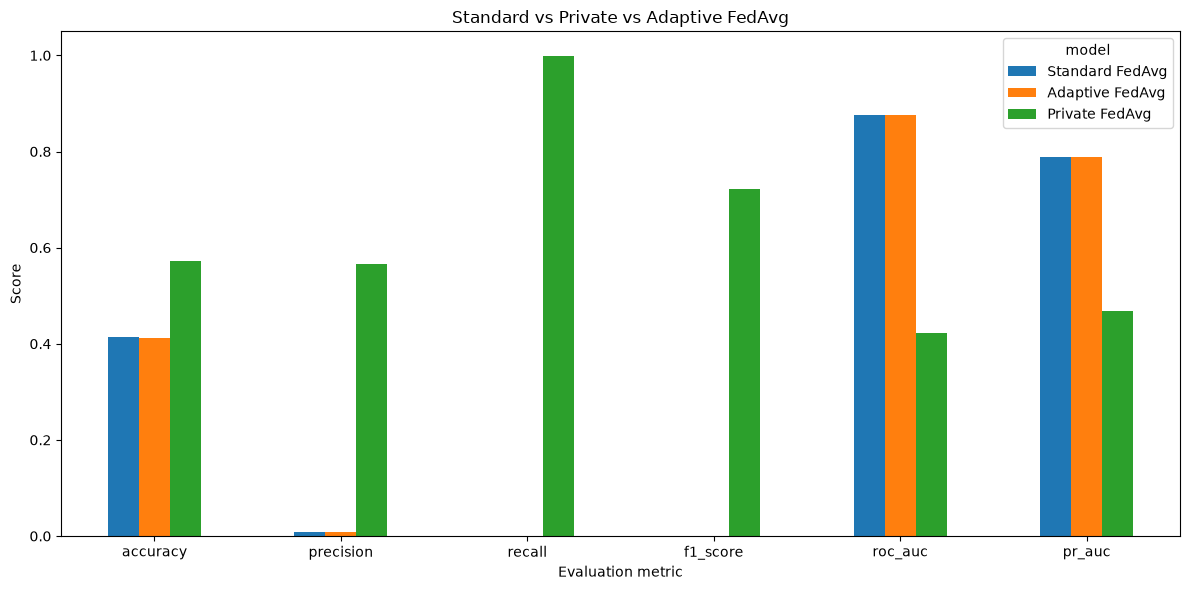

In [5]:
metrics = [
    "accuracy", "precision", "recall",
    "f1_score", "roc_auc", "pr_auc"
]

plot_data = comparison.set_index("model")[metrics].T

ax = plot_data.plot(kind="bar", figsize=(12, 6))
ax.set_title("Standard vs Private vs Adaptive FedAvg")
ax.set_ylabel("Score")
ax.set_xlabel("Evaluation metric")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()

plt.savefig(OUT / "three_model_comparison.png", dpi=150)
plt.show()

In [6]:
expected_files = [
    "three_model_metrics.csv",
    "three_model_predictions.csv",
    "three_model_comparison.png"
]

for filename in expected_files:
    path = OUT / filename
    print(filename, ":", "presentt" if path.exists() else "not theree")

print("\nFinal model comparison:")
display(pd.read_csv(OUT / "three_model_metrics.csv"))

three_model_metrics.csv : presentt
three_model_predictions.csv : presentt
three_model_comparison.png : presentt

Final model comparison:


,model,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,Standard FedAvg,0.413275,0.007968,0.000462,0.000873,0.876633,0.789229
1,Adaptive FedAvg,0.412786,0.007849,0.000462,0.000872,0.876200,0.788830
2,Private FedAvg,0.572790,0.565121,0.999475,0.722007,0.423266,0.469131


- three_model_metrics.csv — scores for all three models.
- three_model_predictions.csv — predictions on the test edges.
- three_model_comparison.png — comparison graph.
Important: Higher accuracy does not automatically mean better privacy. The private model uses your prototype noise mechanism, which does not yet provide a formally verified differential-privacy guarantee.